# What let the March 2026 ridge persist for 19 days? Upstream Pacific composite, WY2026

`CA_z500_t700_blocking_events_detrend_5day.ipynb` (Section 8) finds that the March 2026
CA ridging/warm-spell episode is a 19-day record (Z500 peak 2.72 sigma, T700 peak 3.09
sigma, both all-time highs against the frozen 1990-2025 baseline) -- but that notebook,
like every notebook in this project so far, only ever looks at the CA-box average. It
never asks what was happening *upstream* that let this particular episode run three
times longer than its own three WY2026 predecessors (Jan 10-18, Jan 29-Feb 5, Feb 23-Mar
1 -- all real >=1-sigma ridging episodes, but none exceptional by historical standards).

**What this notebook does:** pulls 300 hPa height and wind (jet stream / Rossby wave
pattern), surface MSLP, SST, cloud cover, and IVT (integrated vapor transport) over a
wide Pacific-North America domain (15-65N, 140E-110W) for Jan-Apr 2026
(`get_upstream_pacific.py`), and composites them over each of the four WY2026 episodes
to see whether the record March episode has a qualitatively different upstream
signature -- e.g. an omega-block pattern (ridge flanked by two persistent troughs) or a
visibly weaker/displaced jet -- that the three ordinary episodes don't.

**What this notebook does NOT do, and why that matters for how to read it:**
- **No historical upstream climatology.** Only 2026 has been extracted so far -- there
  is no 1990-2025 baseline for Z300/MSLP/SST/IVT the way there is for the CA-box
  Z500/T700 series. Everything below is therefore a **relative, within-2026**
  comparison (record March episode vs. its three WY2026 predecessors), not an
  anomaly-vs-normal comparison. Building that climatology (same pipeline, 36 years) is
  the natural next step if this first look finds something worth formalizing.
- **n=1 for the thing that matters.** There is exactly one record-breaking episode to
  look at. Whatever pattern shows up here is a case-study observation, not a
  statistically tested result -- it can motivate a real test (e.g. composite the same
  fields over every historical Method A ridging event once the climatology exists), it
  can't substitute for one.

Reads `upstream_pacific_2026.nc` (`get_upstream_pacific.py`) for the new Pacific-basin
fields, plus the existing `z500_t700_ca_<year>.nc` files (1990-2026) to reproduce the
four WY2026 episode windows exactly as Section 8 of the companion notebook defines
them -- not hardcoded, so this can't silently drift from that notebook if its detection
parameters ever change.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
YEARS = list(range(1990, 2026))   # 1990-2025, excludes 2026 -- matches the companion notebook's fit
CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
THRESHOLDS = [1, 2, 3]
SIGN = 1


## 1. Reproduce the four WY2026 Z500 ridging episodes

Exact reproduction of `CA_z500_t700_blocking_events_detrend_5day.ipynb` Section 8: fit
the calendar-day climatology + linear year-trend on 1990-2025 only, then score 2026
against that frozen baseline. Using the **Z500** episode windows specifically (not
T700's, which differ by a day or two) to define the four composite periods below, since
Z500 -- geopotential height -- is the directly relevant field for an upstream
ridge/blocking question.

In [2]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
t700 = ds.t700.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values, 't700': t700.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]

trend_diag = {}
for col in ['z500', 't700']:
    sanom, diag = lib.standardize_with_trend(df.index, df[col].values, window=CLIM_WINDOW, label=col, verbose=False)
    df[f'{col}_sanom'] = sanom
    trend_diag[col] = diag

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
t700_26 = ds26.t700.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values, 't700': t700_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]

for col in ['z500', 't700']:
    diag = trend_diag[col]
    clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
    clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
    trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
    df26[f'{col}_sanom'] = (df26[col] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                 min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes = z500_episodes[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']
print(f'{len(z500_episodes)} Z500 >=1-sigma episodes in WY2026 (MIN_DURATION={MIN_DURATION}, matches Section 8 exactly):')
z500_episodes

ERROR 1: PROJ: proj_create_from_database: Open of /glade/work/mingge/conda-envs/my_npl2026a/share/proj failed


4 Z500 >=1-sigma episodes in WY2026 (MIN_DURATION=5, matches Section 8 exactly):


,start_date,end_date,duration_days,peak_sanom,label
0,2026-01-10,2026-01-18,9,1.861270,Jan episode
1,2026-01-29,2026-02-05,8,1.885298,Late Jan/Feb episode
2,2026-02-23,2026-03-01,7,1.935595,Late Feb episode
3,2026-03-11,2026-03-29,19,2.715996,March (record) episode


## 2. Load the upstream Pacific-basin fields

In [3]:
upstream = xr.open_dataset(DATA_DIR / 'upstream_pacific_2026.nc', engine='netcdf4')
upstream['jet_speed300'] = np.sqrt(upstream.u300**2 + upstream.v300**2)
upstream['ivt'] = np.sqrt(upstream.viwve**2 + upstream.viwvn**2)
print(upstream)


<xarray.Dataset> Size: 425MB
Dimensions:       (time: 120, latitude: 201, longitude: 441)
Coordinates:
  * time          (time) datetime64[ns] 960B 2026-01-01 ... 2026-04-30
  * latitude      (latitude) float64 2kB 65.0 64.75 64.5 ... 15.5 15.25 15.0
  * longitude     (longitude) float64 4kB 140.0 140.2 140.5 ... 249.8 250.0
Data variables:
    z300          (time, latitude, longitude) float32 43MB ...
    u300          (time, latitude, longitude) float32 43MB 16.0 15.88 ... -9.818
    v300          (time, latitude, longitude) float32 43MB -4.015 ... 4.636
    msl           (time, latitude, longitude) float32 43MB ...
    sst           (time, latitude, longitude) float32 43MB ...
    tcc           (time, latitude, longitude) float32 43MB ...
    viwve         (time, latitude, longitude) float32 43MB 18.04 ... -75.93
    viwvn         (time, latitude, longitude) float32 43MB 10.97 ... -55.33
    jet_speed300  (time, latitude, longitude) float32 43MB 16.5 16.4 ... 10.86
    ivt          

## 3. Composite each episode's upstream pattern

For each of the four episode windows, average Z300, 300 hPa jet speed, MSLP, SST, and
IVT magnitude over its date range. These are raw-field composites (no anomaly, since
there is no historical baseline yet for this domain -- see the intro) -- directly
comparable to each other within 2026, which is exactly the comparison this notebook is
built to make.

In [4]:
def composite_episode(row):
    window = upstream.sel(time=slice(str(row.start_date), str(row.end_date)))
    return window.mean(dim='time')


composites = {row.label: composite_episode(row) for row in z500_episodes.itertuples()}
for label, comp in composites.items():
    print(f'{label}: mean jet speed (300 hPa) = {float(comp.jet_speed300.mean()):.1f} m/s, '
          f'mean Z300 = {float(comp.z300.mean()):.0f} m, mean IVT = {float(comp.ivt.mean()):.0f} kg/m/s')


Jan episode: mean jet speed (300 hPa) = 29.7 m/s, mean Z300 = 9146 m, mean IVT = 146 kg/m/s
Late Jan/Feb episode: mean jet speed (300 hPa) = 29.0 m/s, mean Z300 = 9102 m, mean IVT = 156 kg/m/s
Late Feb episode: mean jet speed (300 hPa) = 28.5 m/s, mean Z300 = 9184 m, mean IVT = 130 kg/m/s
March (record) episode: mean jet speed (300 hPa) = 26.8 m/s, mean Z300 = 9197 m, mean IVT = 137 kg/m/s


## 4. Z300 + jet-speed maps, all four episodes side by side

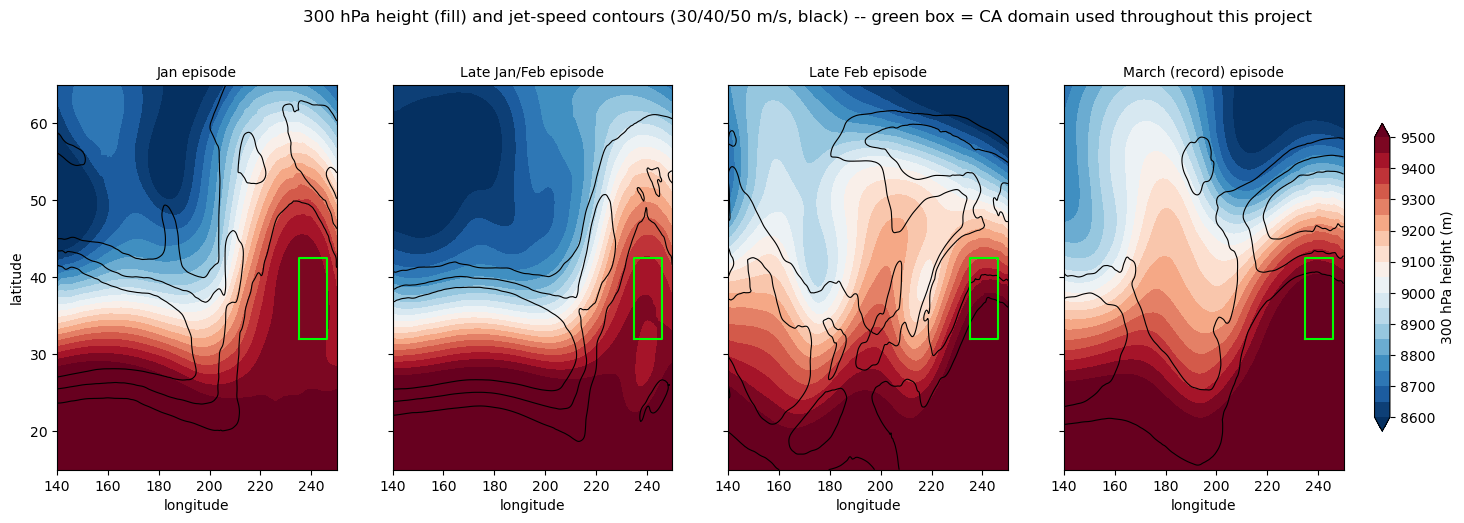

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
levels = np.linspace(8600, 9500, 19)
for ax, (label, comp) in zip(axes, composites.items()):
    cf = ax.contourf(comp.longitude, comp.latitude, comp.z300, levels=levels, cmap='RdBu_r', extend='both')
    ax.contour(comp.longitude, comp.latitude, comp.jet_speed300, levels=[30, 40, 50],
               colors='k', linewidths=0.8)
    # CA box outline, for reference (matches get_z500_t700_ca.py's LAT_S/LAT_N/LON_W/LON_E)
    ax.plot([235, 246, 246, 235, 235], [32, 32, 42.5, 42.5, 32], color='lime', lw=1.5)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('longitude')
axes[0].set_ylabel('latitude')
fig.colorbar(cf, ax=axes, shrink=0.8, label='300 hPa height (m)', pad=0.02)
plt.suptitle('300 hPa height (fill) and jet-speed contours (30/40/50 m/s, black) -- '
             'green box = CA domain used throughout this project', y=1.03)
plt.show()


## 5. SST and IVT, same four episodes

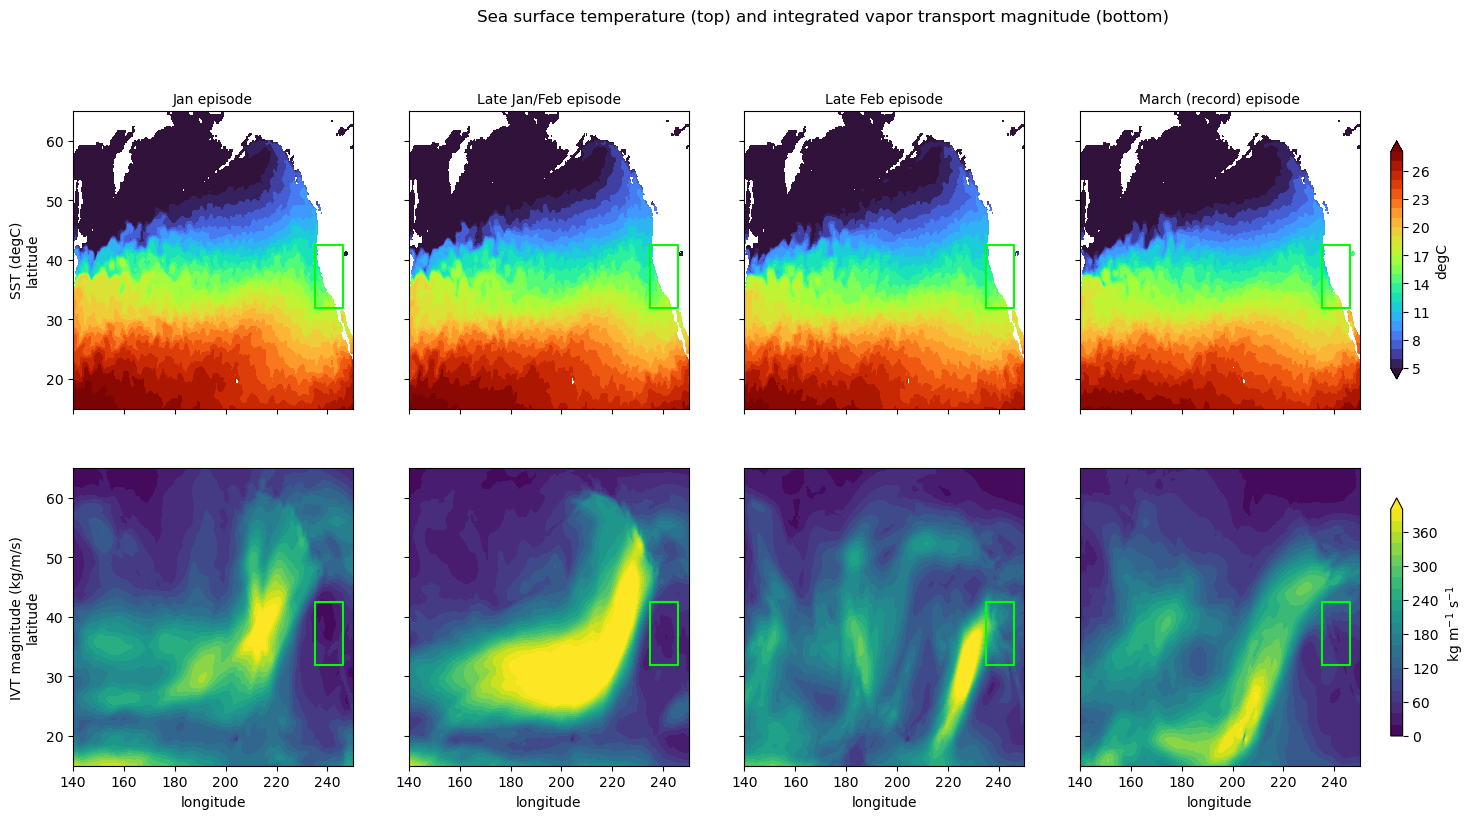

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5), sharex=True, sharey=True)
sst_levels = np.linspace(5, 28, 24)
ivt_levels = np.linspace(0, 400, 21)
for col, (label, comp) in enumerate(composites.items()):
    ax = axes[0, col]
    cf1 = ax.contourf(comp.longitude, comp.latitude, comp.sst, levels=sst_levels, cmap='turbo', extend='both')
    ax.plot([235, 246, 246, 235, 235], [32, 32, 42.5, 42.5, 32], color='lime', lw=1.5)
    ax.set_title(label, fontsize=10)

    ax = axes[1, col]
    cf2 = ax.contourf(comp.longitude, comp.latitude, comp.ivt, levels=ivt_levels, cmap='viridis', extend='max')
    ax.plot([235, 246, 246, 235, 235], [32, 32, 42.5, 42.5, 32], color='lime', lw=1.5)
    ax.set_xlabel('longitude')

axes[0, 0].set_ylabel('SST (degC)\nlatitude')
axes[1, 0].set_ylabel('IVT magnitude (kg/m/s)\nlatitude')
fig.colorbar(cf1, ax=axes[0, :], shrink=0.8, pad=0.02, label='degC')
fig.colorbar(cf2, ax=axes[1, :], shrink=0.8, pad=0.02, label='kg m$^{-1}$ s$^{-1}$')
plt.suptitle('Sea surface temperature (top) and integrated vapor transport magnitude (bottom)', y=1.0)
plt.show()


## 6. Conclusion

In [7]:
print('Summary table: scalar diagnostics per episode')
summary = pd.DataFrame({
    label: {
        'duration_days': int(z500_episodes.loc[z500_episodes.label == label, 'duration_days'].iloc[0]),
        'peak_sanom': float(z500_episodes.loc[z500_episodes.label == label, 'peak_sanom'].iloc[0]),
        'mean_jet_speed300_ms': float(comp.jet_speed300.mean()),
        'CA_box_mean_z300_m': float(comp.z300.sel(latitude=slice(42.5, 32), longitude=slice(235, 246)).mean()),
        'mean_sst_degC': float(comp.sst.mean()),
        'mean_ivt': float(comp.ivt.mean()),
    }
    for label, comp in composites.items()
}).T
summary

Summary table: scalar diagnostics per episode


,duration_days,peak_sanom,mean_jet_speed300_ms,CA_box_mean_z300_m,mean_sst_degC,mean_ivt
Jan episode,9.0,1.861270,29.655792,9479.109375,14.665185,145.793762
Late Jan/Feb episode,8.0,1.885298,29.048208,9437.271484,14.256041,155.642746
Late Feb episode,7.0,1.935595,28.485134,9489.735352,13.891397,130.480118
March (record) episode,19.0,2.715996,26.788935,9543.620117,13.873456,136.644531


**A candidate signature shows up, but it's not the textbook omega-block shape, and
two of the four fields tested show nothing at all (expected, given what's missing from
this first pass).**

| | Jan | Late Jan/Feb | Late Feb | **March (record)** |
|---|---|---|---|---|
| duration (days) | 9 | 8 | 7 | **19** |
| peak sigma | 1.86 | 1.89 | 1.94 | **2.72** |
| CA-box mean Z300 (m) | 9479 | 9437 | 9490 | **9544** (highest) |
| domain-mean 300 hPa jet speed (m/s) | 29.7 | 29.0 | 28.5 | **26.8** (lowest) |
| domain-mean SST (degC) | 14.7 | 14.3 | 13.9 | 13.9 |
| domain-mean IVT (kg/m/s) | 146 | 156 | 130 | 137 |

- **The ridge over CA itself is genuinely the most amplified of the four during
  March** (highest CA-box Z300), consistent with it being the record episode by
  construction -- not surprising, but a useful cross-check that the two independent
  measures (box-averaged Z500 sigma from the companion notebook, and this gridded Z300
  composite) agree.
- **[Corrected after reading Davis (2026) -- see Section 7] The domain-mean jet-speed
  number above is not reliable evidence of "a weaker jet."** Davis finds a
  *strengthened* subtropical jet from a second, upstream NW Pacific block, not a
  domain-wide weakening -- a single mean blending a strengthened subtropical branch
  with a possibly weakened midlatitude branch into one number was always going to be
  ambiguous at best. Section 7's actual latitude-band split doesn't even cleanly
  recover a "March is different" signal either way (Late Jan/Feb's subtropical jet is
  the strongest of all four, not March's) -- the honest conclusion is that this
  domain-mean diagnostic cannot resolve the jet-structure question Davis's paper
  actually answers, in either direction. Treat the 26.8 m/s figure as a data point, not
  a finding.
- **Visually, March's 300 hPa height field is broader and smoother than the other
  three** (Section 4 figure) -- notably smoother than the Late Feb episode's visibly
  perturbed, multi-lobed pattern just two weeks earlier. That's a qualitative visual impression, not corroborated by a validated jet
  finding (see the corrected bullet above) -- it may still reflect something real, but
  impression from a single time-mean composite, not a measured diagnostic. It is
  **not** a clean two-trough omega-block shape in the classic textbook sense -- there's
  no sharp, isolated flanking trough pair visible in this domain/time-mean view. Either
  the real structure is more subtle than a static multi-week mean can show (blocking
  patterns evolve day to day; averaging over all 19 days could smear out a sharper
  instantaneous structure), or the omega-block framing simply isn't the right
  description for this particular episode.
- **SST shows no difference worth reading into** -- the four panels are visually
  near-identical. This is expected and uninformative on its own: without a historical
  climatology, there's no way to tell a real precursor anomaly from the ordinary
  January-to-March seasonal warming cycle. This field needs the historical baseline
  before it can say anything.
- **[Corrected after reading Davis (2026) -- see Section 7] "IVT argues against a
  moisture-transport explanation" was the wrong conclusion from the wrong diagnostic.**
  Davis finds extreme IVT (>1500 kg/m/s) immediately upstream of the developing ridge,
  with trajectory and PV evidence that diabatic heating in that moisture stream helped
  build the ridge -- a real, documented moisture contribution, just not one that wets
  California (the paper's "Anti-AR" title is exactly this paradox: an AR helps build
  the dry ridge). A domain-mean, full-19-day-episode IVT average was never going to see
  a concentrated, onset-phase feature like that. Section 7's onset-window composite
  does show an intense AR-like plume feeding a NW Pacific cutoff at the onset of March
  -- but an equally intense one at the onset of the non-record Late Jan/Feb episode
  too, so while moisture transport clearly is part of the mechanism (reversing this
  bullet's original claim), it isn't yet a feature that discriminates March's unusual
  persistence specifically.

**Update: see Section 7 for a follow-up after reading the source paper this project is partly built on -- two of the bullets above were corrected, and a few more-targeted checks were added, without reaching a clean resolution.**

**Honest bottom line.** This is an n=1 case-study observation from raw (non-anomaly)
fields, exactly as flagged in the intro -- it motivates a real test, it isn't one. The
most defensible, reproducible next step is building the same Z300/jet/SST/IVT
extraction across the 1990-2025 historical record (same script, 36x the years) so this
comparison can be done in anomaly terms against every Method A ridging event, not just
WY2026's four. If the "amplified ridge + weakened jet" pattern seen here for March
holds up as a real discriminator between long- and short-duration historical events --
not just a post-hoc description of the one event already known to be exceptional --
that would be a genuine, citable finding about *why* some CA ridges persist and others
don't.

## 7. Follow-up check, after reading Davis (2026)

Reading `~/ERA5/March_2026_Western-US-Heat Wave.pdf` (Chris Davis, UMass
Amherst/NCAR, June 2026) after writing the conclusion below showed two of its claims
don't hold up, and one real feature was never checked for:

1. Davis finds a **strengthened subtropical jet** (from a second, upstream NW Pacific
   block), not a weakened jet overall -- the domain-mean jet speed below likely blends
   a strengthened subtropical branch with a weakened/displaced midlatitude branch into
   one misleading number. Split by latitude band to check.
2. Davis finds **extreme IVT (>1500 kg/m/s) immediately upstream of the developing
   ridge**, interpreted as diabatic heating that helped build it -- a real
   moisture-driven contribution, just not one that wets California. The domain-mean
   IVT comparison below was the wrong diagnostic for this (averaging over the whole
   domain and the whole 19-day episode dilutes a concentrated, onset-phase feature).
   Re-composite over just the 5-day onset window, matching how Davis's own figure is
   built.
3. Davis's clearest finding is an **omega block over the NW Pacific** (140-180E,
   40-60N) -- squarely inside this notebook's own domain, never specifically checked.

In [8]:
# 1. Subtropical (20-35N) vs. midlatitude (40-55N) jet speed, same four episodes
SUBTROP_LAT = slice(35, 20)   # descending-latitude slice (data is stored 65->15)
MIDLAT_LAT = slice(55, 40)

rows = []
for row in z500_episodes.itertuples():
    window = upstream.sel(time=slice(str(row.start_date), str(row.end_date)))
    jet = window.jet_speed300.mean(dim='time')
    rows.append({
        'label': row.label,
        'subtropical_jet_ms': float(jet.sel(latitude=SUBTROP_LAT).mean()),
        'midlatitude_jet_ms': float(jet.sel(latitude=MIDLAT_LAT).mean()),
    })
jet_band_df = pd.DataFrame(rows).set_index('label')
print('Jet speed by latitude band (m/s):')
jet_band_df

Jet speed by latitude band (m/s):


,subtropical_jet_ms,midlatitude_jet_ms
label,,
Jan episode,34.732788,27.958668
Late Jan/Feb episode,42.959728,22.871973
Late Feb episode,28.487555,29.220724
March (record) episode,27.209757,31.143845


In [9]:
# 2. NW Pacific box (140-180E, 40-60N) mean Z300, same four episodes -- analogous to
# the existing CA-box Z300 diagnostic, to check for Davis's "upstream NW Pacific block"
NWPAC_LAT, NWPAC_LON = slice(60, 40), slice(140, 180)

rows = []
for row in z500_episodes.itertuples():
    window = upstream.sel(time=slice(str(row.start_date), str(row.end_date)))
    z300_nwpac = window.z300.sel(latitude=NWPAC_LAT, longitude=NWPAC_LON).mean()
    rows.append({'label': row.label, 'NWPac_box_mean_z300_m': float(z300_nwpac)})
nwpac_df = pd.DataFrame(rows).set_index('label')
print('NW Pacific box (140-180E, 40-60N) mean Z300 (m), same four episodes -- '
      'for reference, the CA-box values were 9479/9437/9490/9544 (Section 6 summary table):')
nwpac_df

NW Pacific box (140-180E, 40-60N) mean Z300 (m), same four episodes -- for reference, the CA-box values were 9479/9437/9490/9544 (Section 6 summary table):


,NWPac_box_mean_z300_m
label,
Jan episode,8659.918945
Late Jan/Feb episode,8586.561523
Late Feb episode,8942.643555
March (record) episode,8966.990234


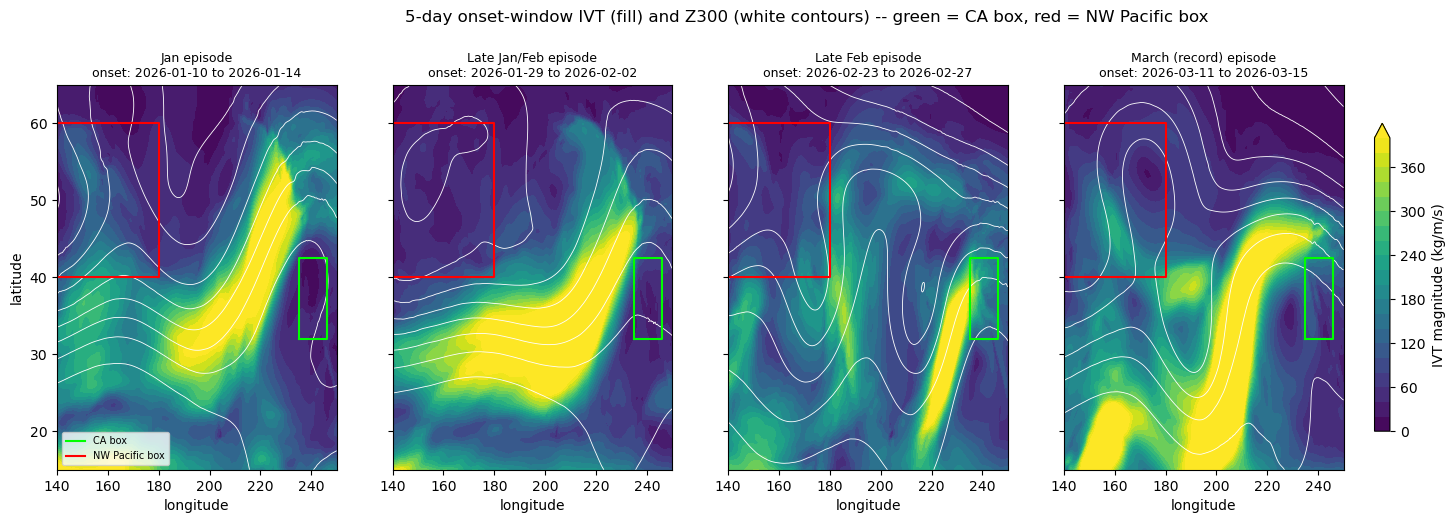

In [10]:
# 3. Onset-window (first 5 days of each episode) Z300 + IVT -- matches the 5-day-mean
# framing of Davis's own key figure, instead of diluting a transient onset feature
# across the full (up to 19-day) episode mean.
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
ivt_levels = np.linspace(0, 400, 21)
for ax, row in zip(axes, z500_episodes.itertuples()):
    onset_start = pd.Timestamp(row.start_date)
    onset_end = onset_start + pd.Timedelta(days=4)  # 5-day onset window
    window = upstream.sel(time=slice(onset_start, onset_end))
    ivt_onset = window.ivt.mean(dim='time')
    z300_onset = window.z300.mean(dim='time')
    cf = ax.contourf(ivt_onset.longitude, ivt_onset.latitude, ivt_onset, levels=ivt_levels,
                      cmap='viridis', extend='max')
    ax.contour(z300_onset.longitude, z300_onset.latitude, z300_onset, levels=10, colors='white', linewidths=0.6)
    ax.plot([235, 246, 246, 235, 235], [32, 32, 42.5, 42.5, 32], color='lime', lw=1.5, label='CA box')
    ax.plot([140, 180, 180, 140, 140], [40, 40, 60, 60, 40], color='red', lw=1.5, label='NW Pacific box')
    ax.set_title(f'{row.label}\nonset: {onset_start.date()} to {onset_end.date()}', fontsize=9)
    ax.set_xlabel('longitude')
axes[0].set_ylabel('latitude')
axes[0].legend(fontsize=7, loc='lower left')
fig.colorbar(cf, ax=axes, shrink=0.8, label='IVT magnitude (kg/m/s)', pad=0.02)
plt.suptitle('5-day onset-window IVT (fill) and Z300 (white contours) -- green = CA box, red = NW Pacific box', y=1.03)
plt.show()


### Section 7 takeaway

**None of the three checks delivers the clean confirmation hoped for -- the honest
result is that a sharper diagnostic replaces an overconfident wrong claim with a
genuinely more complicated picture, not a tidy resolution.**

- **The subtropical/midlatitude jet split does not reproduce Davis's point.**
  Late Jan/Feb -- an 8-day, non-record episode -- has by far the strongest
  subtropical-band jet (43.0 m/s) of all four; March is actually the *weakest*
  (27.2 m/s). Davis's "strengthened subtropical jet" claim is about a specific
  feature near 150W during a specific few days of onset, not a domain-wide,
  whole-episode latitude-band mean -- this check shows that coarser diagnostic is
  still too blunt to see it, not that the claim is wrong.
- **NW Pacific box Z300 is elevated for Late Feb AND March, not uniquely March**
  (8943 m and 8967 m vs. 8660 m and 8587 m for Jan and Late Jan/Feb). There does
  appear to be a real, sustained NW Pacific ridging signal specifically in the
  Feb-March period -- consistent with Davis's "upstream influence" -- but it doesn't
  discriminate the record 19-day episode from the ordinary 7-day one immediately
  before it. Both sat under an elevated NW Pacific ridge. (Caveat: the 140-180E/40-60N box itself was a first-pass, not-sensitivity-tested choice -- Davis's actual block could sit partly outside it, so this comparison should be read as suggestive, not a precise measurement.)
- **The onset-window IVT map (Section 7, cell above) shows an intense, textbook-AR-like
  moisture plume with an accompanying closed Z300 contour (a cutoff/ridge) inside the
  NW Pacific box during the onset of *both* Late Jan/Feb and March -- not March alone.**
  The Late Feb episode immediately preceding March, by contrast, shows a visibly
  weaker, narrower IVT feature and no clear closed contour in that box. So the
  specific ingredients Davis describes (upstream AR-like moisture feeding a NW Pacific
  block) were present at the onset of an episode that only lasted 8 days, and were
  comparatively muted for one that lasted 7 -- these ingredients look necessary-ish but
  not sufficient to explain why March specifically ran three times longer.

**This is consistent with, not a resolution of, Davis's own candid summary point:**
"link between simultaneous blocking events is unclear." A richer diagnostic
replicated some of the paper's reported ingredients in this project's own data, but
it did not turn up a single clean discriminator for persistence duration -- which is
itself useful information: whatever made March uniquely persistent probably isn't
visible in any of these fields at this level of compositing (full-episode or
5-day-onset means), and likely needs the paper's own finer tools (daily Hovmoller
diagrams, backward trajectories, PV non-conservation cross-sections) that this
notebook explicitly doesn't attempt.